In [1]:
!rm -rf /kaggle/working/organized_images

In [2]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
df = pd.read_csv('/kaggle/input/fashion-product-images-dataset/fashion-dataset/images.csv')


import os

# Lista todos los archivos y carpetas en el directorio raíz del dataset
dataset_dir = "/kaggle/input/fashion-product-images-dataset"
print(os.listdir(dataset_dir))


['fashion-dataset']


In [3]:
import pandas as pd

# Cargar el archivo CSV
df = pd.read_csv('/kaggle/input/fashion-product-images-dataset/fashion-dataset/images.csv')

# Mostrar las primeras filas del dataframe
df.head()

# Verifica la cantidad de datos y las columnas
print(df.shape)
print(df.columns)


(44446, 2)
Index(['filename', 'link'], dtype='object')


In [4]:
# Mostrar algunas filas del DataFrame
print(df.head())

# Verificar si hay valores nulos en las columnas
print(df.isnull().sum())


    filename                                               link
0  15970.jpg  http://assets.myntassets.com/v1/images/style/p...
1  39386.jpg  http://assets.myntassets.com/v1/images/style/p...
2  59263.jpg  http://assets.myntassets.com/v1/images/style/p...
3  21379.jpg  http://assets.myntassets.com/v1/images/style/p...
4  53759.jpg  http://assets.myntassets.com/v1/images/style/p...
filename    0
link        0
dtype: int64


In [5]:
import os

image_dir = '/kaggle/input/fashion-product-images-dataset/fashion-dataset/images'
sample_image_path = os.path.join(image_dir, df['filename'][0])

print(f"Sample image path: {sample_image_path}")
print(f"File exists: {os.path.exists(sample_image_path)}")


Sample image path: /kaggle/input/fashion-product-images-dataset/fashion-dataset/images/15970.jpg
File exists: True


In [6]:
import pandas as pd

# Cargar el CSV ignorando las líneas malformadas
styles_df = pd.read_csv('/kaggle/input/fashion-product-images-dataset/fashion-dataset/styles.csv', on_bad_lines='skip')

# Explorar las primeras filas
print(styles_df.head())


      id gender masterCategory subCategory  articleType baseColour  season  \
0  15970    Men        Apparel     Topwear       Shirts  Navy Blue    Fall   
1  39386    Men        Apparel  Bottomwear        Jeans       Blue  Summer   
2  59263  Women    Accessories     Watches      Watches     Silver  Winter   
3  21379    Men        Apparel  Bottomwear  Track Pants      Black    Fall   
4  53759    Men        Apparel     Topwear      Tshirts       Grey  Summer   

     year   usage                             productDisplayName  
0  2011.0  Casual               Turtle Check Men Navy Blue Shirt  
1  2012.0  Casual             Peter England Men Party Blue Jeans  
2  2016.0  Casual                       Titan Women Silver Watch  
3  2011.0  Casual  Manchester United Men Solid Black Track Pants  
4  2012.0  Casual                          Puma Men Grey T-shirt  


In [7]:
# filename es el nombre correcto de la columna que contiene los nombres de archivo
styles_df['filename'] = styles_df['id'].astype(str) + '.jpg'

# Crear un diccionario para mapear archivos con sus categorías
filename_to_class = dict(zip(styles_df['filename'], styles_df['articleType']))


In [8]:
import os
import shutil

# Crear un directorio base para las imágenes organizadas
base_dir = '/kaggle/working/organized_images'
os.makedirs(base_dir, exist_ok=True)

# Directorio donde están actualmente las imágenes
source_dir = '/kaggle/input/fashion-product-images-dataset/fashion-dataset/images'

for filename, class_name in filename_to_class.items():
    # Crear la carpeta de clase si no existe
    class_dir = os.path.join(base_dir, class_name)
    os.makedirs(class_dir, exist_ok=True)
    
    # Ruta de origen y destino
    src_path = os.path.join(source_dir, filename)
    dst_path = os.path.join(class_dir, filename)
    
    # Copiar la imagen al directorio de su clase
    if os.path.exists(src_path):
        shutil.copy(src_path, dst_path)

# Comprimir el directorio organizado en un archivo .zip
# shutil.make_archive(base_dir, 'zip', base_dir)

# print(f"Archivo comprimido guardado en: {zip_filename}")

In [9]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.1  # Separar un 10% de los datos para validación
)

train_generator = datagen.flow_from_directory(
    directory=base_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    subset='training'
)

validation_generator = datagen.flow_from_directory(
    directory=base_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    subset='validation'
)


2024-08-13 06:00:16.017028: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-08-13 06:00:16.017131: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-08-13 06:00:16.148723: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


Found 40043 images belonging to 143 classes.
Found 4376 images belonging to 143 classes.


In [10]:
# Extraer un lote de datos del generador
sample_batch = next(train_generator)

# El lote extraído es una tupla (imágenes, etiquetas)
images, labels = sample_batch

# Mostrar la forma de las imágenes y etiquetas
print("Shape of images:", images.shape)
print("Shape of labels:", labels.shape)


Shape of images: (32, 224, 224, 3)
Shape of labels: (32, 143)


In [11]:
import tensorflow as tf
print(tf.__version__)


2.15.0


In [12]:
from tensorflow.keras.applications import VGG16
from tensorflow.keras import layers, models

# Añadir una capa Input explícita
input_layer = layers.Input(shape=(224, 224, 3))

# Cargar el modelo VGG16 preentrenado sin la capa superior
base_model = VGG16(weights='imagenet', include_top=False)(input_layer)

# Añadir las capas adicionales
x = layers.Flatten()(base_model)
x = layers.Dense(256, activation='relu')(x)
x = layers.Dropout(0.5)(x)
output_layer = layers.Dense(143, activation='softmax')(x)

# Crear el modelo completo
model = models.Model(inputs=input_layer, outputs=output_layer)

# Compilar el modelo
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

model.summary()


58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     6,422,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 143)            │        36,751 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,174,223 (80.77 MB)

 Trainable params: 21,174,223 (80.77 MB)

 Non-trainable params: 0 (0.00 B)

In [13]:
history = model.fit(
    train_generator,
    steps_per_epoch=train_generator.samples // train_generator.batch_size,
    validation_data=validation_generator,
    validation_steps=validation_generator.samples // validation_generator.batch_size,
    epochs=10  # Ajusta según sea necesario
)


Epoch 1/10


/opt/conda/lib/python3.10/site-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()
2024-08-13 06:00:44.892772: E external/local_xla/xla/service/gpu/buffer_comparator.cc:1137] Difference at 0: 4.63498, expected 3.85968
2024-08-13 06:00:44.892821: E external/local_xla/xla/service/gpu/buffer_comparator.cc:1137] Difference at 3: 6.55784, expected 5.78254
2024-08-13 06:00:44.892830: E external/local_xla/xla/service/gpu/buffer_comparator.cc:1137] Difference at 4: 6.61282, expected 5.83752
2024-08-13 06:00:44.892838: E external/local_xla/xla/service/gpu/buffer_comparator.cc:1137] Difference at 6: 6.34499, expected 5.56968
2024-08-13 06:00:44.892846: E external/local_xla/xla/service/gpu/buffer_comparator.cc:11

 754/1251 ━━━━━━━━━━━━━━━━━━━━ 4:47 578ms/step - accuracy: 0.2148 - loss: 4.1690

2024-08-13 06:08:37.675115: E external/local_xla/xla/service/gpu/buffer_comparator.cc:1137] Difference at 0: 4.18376, expected 3.42997
2024-08-13 06:08:37.675175: E external/local_xla/xla/service/gpu/buffer_comparator.cc:1137] Difference at 1: 5.33565, expected 4.58186
2024-08-13 06:08:37.675184: E external/local_xla/xla/service/gpu/buffer_comparator.cc:1137] Difference at 2: 4.70509, expected 3.95129
2024-08-13 06:08:37.675192: E external/local_xla/xla/service/gpu/buffer_comparator.cc:1137] Difference at 3: 5.361, expected 4.60721
2024-08-13 06:08:37.675200: E external/local_xla/xla/service/gpu/buffer_comparator.cc:1137] Difference at 4: 5.17522, expected 4.42143
2024-08-13 06:08:37.675210: E external/local_xla/xla/service/gpu/buffer_comparator.cc:1137] Difference at 5: 4.39461, expected 3.64082
2024-08-13 06:08:37.675218: E external/local_xla/xla/service/gpu/buffer_comparator.cc:1137] Difference at 6: 4.45438, expected 3.70059
2024-08-13 06:08:37.675226: E external/local_xla/xla/serv

1251/1251 ━━━━━━━━━━━━━━━━━━━━ 896s 679ms/step - accuracy: 0.2427 - loss: 69.4733 - val_accuracy: 0.1613 - val_loss: 3.5934
Epoch 2/10
   1/1251 ━━━━━━━━━━━━━━━━━━━━ 4:08 199ms/step - accuracy: 0.0938 - loss: 3.5403

/opt/conda/lib/python3.10/contextlib.py:153: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self.gen.throw(typ, value, traceback)
2024-08-13 06:15:30.391912: E external/local_xla/xla/service/gpu/buffer_comparator.cc:1137] Difference at 50188: 2.79675, expected 2.40555
2024-08-13 06:15:30.391977: E external/local_xla/xla/service/gpu/buffer_comparator.cc:1137] Difference at 50357: 2.77153, expected 2.38033
2024-08-13 06:15:30.391987: E external/local_xla/xla/service/gpu/buffer_comparator.cc:1137] Difference at 50399: 2.10715, expected 1.71595
2024-08-13 06:15:30.392017: E external/local_xla/xla/service/gpu/buffer_comparator.cc:1137] Difference at 55327: 2.85302, expected 2.46182
2024-08-13 06:15:30.392745: E external/local_xla/xla/service/gpu/buffer_comparator.cc:1137] Difference at 200704: 4.41732, 

1251/1251 ━━━━━━━━━━━━━━━━━━━━ 13s 10ms/step - accuracy: 0.0938 - loss: 3.5403 - val_accuracy: 0.1667 - val_loss: 3.5558
Epoch 3/10
1251/1251 ━━━━━━━━━━━━━━━━━━━━ 761s 605ms/step - accuracy: 0.1564 - loss: 3.6741 - val_accuracy: 0.1615 - val_loss: 3.5737
Epoch 4/10
1251/1251 ━━━━━━━━━━━━━━━━━━━━ 1s 313us/step - accuracy: 0.1250 - loss: 3.7712 - val_accuracy: 0.1250 - val_loss: 3.5316
Epoch 5/10
1251/1251 ━━━━━━━━━━━━━━━━━━━━ 760s 604ms/step - accuracy: 0.1592 - loss: 3.6663 - val_accuracy: 0.1620 - val_loss: 3.5719
Epoch 6/10
1251/1251 ━━━━━━━━━━━━━━━━━━━━ 0s 227us/step - accuracy: 0.0938 - loss: 3.9501 - val_accuracy: 0.0417 - val_loss: 4.0297
Epoch 7/10
1251/1251 ━━━━━━━━━━━━━━━━━━━━ 729s 580ms/step - accuracy: 0.1577 - loss: 3.6561 - val_accuracy: 0.1608 - val_loss: 3.5758
Epoch 8/10
1251/1251 ━━━━━━━━━━━━━━━━━━━━ 1s 320us/step - accuracy: 0.0938 - loss: 3.8572 - val_accuracy: 0.2500 - val_loss: 3.2633
Epoch 9/10
1251/1251 ━━━━━━━━━━━━━━━━━━━━ 735s 584ms/step - accuracy: 0.1576 - lo

In [14]:
loss, accuracy = model.evaluate(validation_generator)
print(f'Validation Accuracy: {accuracy*100:.2f}%')


137/137 ━━━━━━━━━━━━━━━━━━━━ 102s 741ms/step - accuracy: 0.1732 - loss: 3.5603
Validation Accuracy: 16.13%


In [15]:
model.save('/kaggle/working/fashion_model.h5')


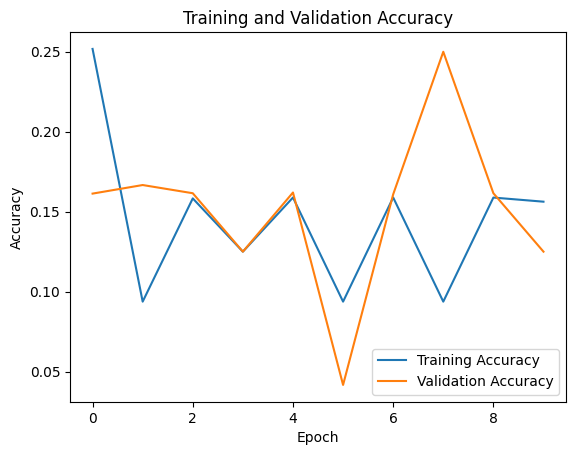

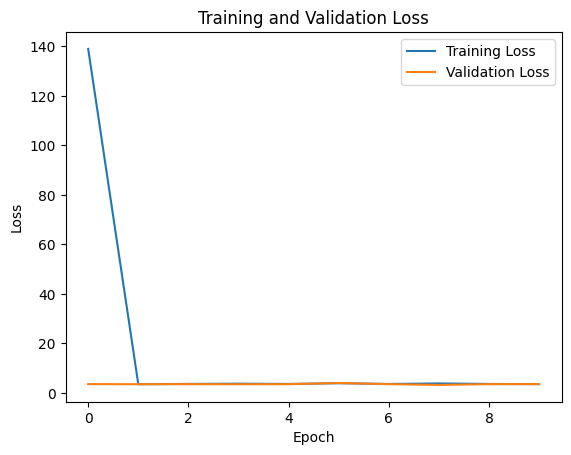

In [16]:
import matplotlib.pyplot as plt

# Graficar la precisión del entrenamiento y validación por época
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')
plt.show()

# Graficar la pérdida del entrenamiento y validación por época
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.show()


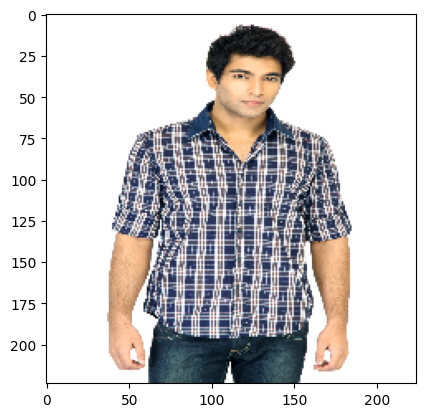

In [17]:
from tensorflow.keras.preprocessing.image import load_img, img_to_array
import numpy as np

# Ruta de la imagen para probar
image_path = '/kaggle/input/fashion-product-images-dataset/fashion-dataset/images/15970.jpg'  # Cambia a la ruta de tu imagen

# Cargar la imagen con el tamaño esperado por el modelo
img = load_img(image_path, target_size=(224, 224))

# Convertir la imagen a un array de numpy y expandir dimensiones
img_array = img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)  # Añadir una dimensión para el lote

# Preprocesar la imagen de la misma manera que los datos de entrenamiento
img_array /= 255.0  # Si usaste rescale=1./255 en ImageDataGenerator

# Mostrar la imagen
plt.imshow(img_array[0])
plt.show()


In [18]:
# Realizar la predicción
predictions = model.predict(img_array)

# La predicción es un vector con probabilidades para cada clase
predicted_class = np.argmax(predictions, axis=1)

# Mostrar la clase predicha
print(f'Predicted class: {predicted_class[0]}')


2024-08-13 07:08:01.540333: E external/local_xla/xla/service/gpu/buffer_comparator.cc:1137] Difference at 0: 4.42855, expected 3.64542
2024-08-13 07:08:01.540394: E external/local_xla/xla/service/gpu/buffer_comparator.cc:1137] Difference at 1: 5.87036, expected 5.08723
2024-08-13 07:08:01.540404: E external/local_xla/xla/service/gpu/buffer_comparator.cc:1137] Difference at 2: 6.04003, expected 5.2569
2024-08-13 07:08:01.540423: E external/local_xla/xla/service/gpu/buffer_comparator.cc:1137] Difference at 3: 6.22034, expected 5.43722
2024-08-13 07:08:01.540430: E external/local_xla/xla/service/gpu/buffer_comparator.cc:1137] Difference at 4: 4.90026, expected 4.11714
2024-08-13 07:08:01.540438: E external/local_xla/xla/service/gpu/buffer_comparator.cc:1137] Difference at 5: 5.21068, expected 4.42756
2024-08-13 07:08:01.540446: E external/local_xla/xla/service/gpu/buffer_comparator.cc:1137] Difference at 6: 5.92061, expected 5.13748
2024-08-13 07:08:01.540454: E external/local_xla/xla/ser

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
Predicted class: 63


In [19]:

class_indices = train_generator.class_indices
class_labels = {v: k for k, v in class_indices.items()}

# Obtener el nombre de la clase predicha
predicted_class_name = class_labels[predicted_class[0]]

print(f'Predicted class name: {predicted_class_name}')


Predicted class name: Kurtas


In [20]:
# Obtener el mapeo de índices a nombres de clases desde el generador de datos
class_indices = train_generator.class_indices

# Invertir el mapeo para obtener un diccionario de índices a nombres de clases
classes = {v: k for k, v in class_indices.items()}

# Mostrar las clases
print("Clases disponibles:")
for index, class_name in classes.items():
    print(f"Clase {index}: {class_name}")


Clases disponibles:
Clase 0: Accessory Gift Set
Clase 1: Baby Dolls
Clase 2: Backpacks
Clase 3: Bangle
Clase 4: Basketballs
Clase 5: Bath Robe
Clase 6: Beauty Accessory
Clase 7: Belts
Clase 8: Blazers
Clase 9: Body Lotion
Clase 10: Body Wash and Scrub
Clase 11: Booties
Clase 12: Boxers
Clase 13: Bra
Clase 14: Bracelet
Clase 15: Briefs
Clase 16: Camisoles
Clase 17: Capris
Clase 18: Caps
Clase 19: Casual Shoes
Clase 20: Churidar
Clase 21: Clothing Set
Clase 22: Clutches
Clase 23: Compact
Clase 24: Concealer
Clase 25: Cufflinks
Clase 26: Cushion Covers
Clase 27: Deodorant
Clase 28: Dresses
Clase 29: Duffel Bag
Clase 30: Dupatta
Clase 31: Earrings
Clase 32: Eye Cream
Clase 33: Eyeshadow
Clase 34: Face Moisturisers
Clase 35: Face Scrub and Exfoliator
Clase 36: Face Serum and Gel
Clase 37: Face Wash and Cleanser
Clase 38: Flats
Clase 39: Flip Flops
Clase 40: Footballs
Clase 41: Formal Shoes
Clase 42: Foundation and Primer
Clase 43: Fragrance Gift Set
Clase 44: Free Gifts
Clase 45: Gloves
Cla

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step


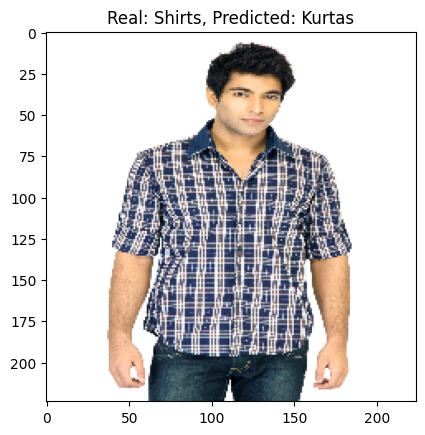

In [21]:
from tensorflow.keras.preprocessing.image import load_img, img_to_array
import numpy as np
import matplotlib.pyplot as plt

# Ruta de la imagen que quieres probar
image_id = 15970  # ID de la imagen
image_filename = f'{image_id}.jpg'
image_path = f'/kaggle/input/fashion-product-images-dataset/fashion-dataset/images/{image_filename}'

# Obtener la etiqueta real de la imagen desde el DataFrame
real_label = styles_df.loc[styles_df['id'] == image_id, 'articleType'].values[0]

# Cargar la imagen
img = load_img(image_path, target_size=(224, 224))

# Convertir la imagen a un array de numpy y expandir dimensiones
img_array = img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)
img_array /= 255.0  # Si usaste rescale=1./255 en ImageDataGenerator

# Realizar la predicción
predictions = model.predict(img_array)
predicted_class = np.argmax(predictions, axis=1)

# Obtener el nombre de la clase predicha
predicted_class_name = classes[predicted_class[0]]

# Mostrar la imagen con la predicción y la etiqueta real
plt.imshow(img)
plt.title(f'Real: {real_label}, Predicted: {predicted_class_name}')
plt.show()


In [22]:
from tensorflow.keras.preprocessing.image import load_img, img_to_array
import numpy as np
import os

# Directorio donde están las imágenes de prueba
test_dir = '/kaggle/input/fashion-product-images-dataset/fashion-dataset/images'

# Lista de archivos de imagen (asegúrate de que sean nombres de archivos válidos)
image_files = ['15970.jpg', '39386.jpg', '59263.jpg']  # Reemplaza con los archivos que quieras probar

# Lista para almacenar las imágenes cargadas y las etiquetas reales
images = []
real_labels = []

# Cargar y preprocesar las imágenes
for image_file in image_files:
    # Obtener el ID del archivo (sin la extensión)
    image_id = os.path.splitext(image_file)[0]
    
    # Obtener la etiqueta real desde el DataFrame
    real_label = styles_df.loc[styles_df['id'] == int(image_id), 'articleType'].values[0]
    
    # Cargar y preprocesar la imagen
    img_path = os.path.join(test_dir, image_file)
    img = load_img(img_path, target_size=(224, 224))  # Ajusta el tamaño según el modelo
    img_array = img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)  # Añadir una dimensión para el lote
    img_array /= 255.0  # Normalizar la imagen si usaste rescale=1./255 durante el entrenamiento

    # Almacenar la imagen y la etiqueta real
    images.append(img_array)
    real_labels.append(real_label)

# Convertir la lista de imágenes en un array numpy
images = np.vstack(images)

# Ahora puedes usar la lista `real_labels` y el array `images` para hacer predicciones


In [23]:
# Hacer predicciones
predictions = model.predict(images)

# Convertir las predicciones a clases
predicted_classes = np.argmax(predictions, axis=1)


2024-08-13 07:08:09.816481: E external/local_xla/xla/service/gpu/buffer_comparator.cc:1137] Difference at 0: 3.54907, expected 2.92871
2024-08-13 07:08:09.816539: E external/local_xla/xla/service/gpu/buffer_comparator.cc:1137] Difference at 2: 4.96556, expected 4.3452
2024-08-13 07:08:09.816550: E external/local_xla/xla/service/gpu/buffer_comparator.cc:1137] Difference at 4: 5.02093, expected 4.40057
2024-08-13 07:08:09.816559: E external/local_xla/xla/service/gpu/buffer_comparator.cc:1137] Difference at 5: 4.88945, expected 4.26909
2024-08-13 07:08:09.816568: E external/local_xla/xla/service/gpu/buffer_comparator.cc:1137] Difference at 6: 5.14523, expected 4.52487
2024-08-13 07:08:09.816577: E external/local_xla/xla/service/gpu/buffer_comparator.cc:1137] Difference at 7: 4.19105, expected 3.57069
2024-08-13 07:08:09.816586: E external/local_xla/xla/service/gpu/buffer_comparator.cc:1137] Difference at 8: 3.8535, expected 3.23314
2024-08-13 07:08:09.816595: E external/local_xla/xla/serv

1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step


In [24]:
# Mostrar las predicciones
for i, image_file in enumerate(image_files):
    predicted_class = predicted_classes[i]
    predicted_class_name = classes[predicted_class]  # Las classes son tu diccionario de mapeo
    real_class_name = real_labels[i]
    print(f"Imagen: {image_file} - Predicción: {predicted_class_name},  Real: {real_class_name}")


Imagen: 15970.jpg - Predicción: Kurtas,  Real: Shirts
Imagen: 39386.jpg - Predicción: Shirts,  Real: Jeans
Imagen: 59263.jpg - Predicción: Shirts,  Real: Watches


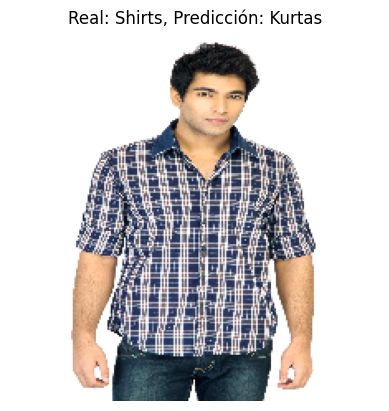

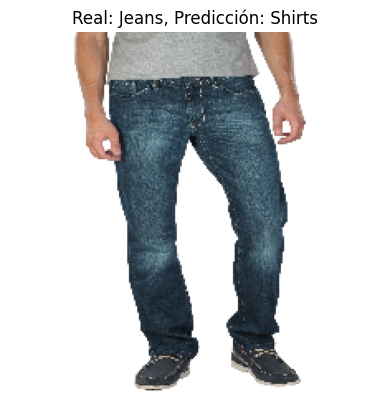

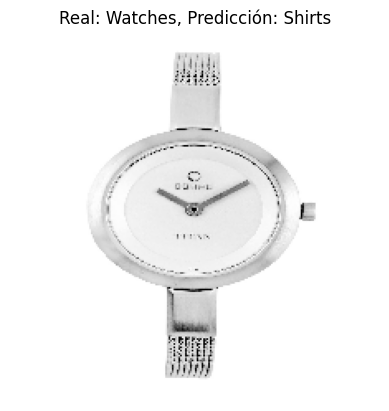

In [25]:
import matplotlib.pyplot as plt

# Visualizar las imágenes junto con sus predicciones y clases reales
for i, image_file in enumerate(image_files):
    img_path = os.path.join(test_dir, image_file)
    img = load_img(img_path, target_size=(224, 224))
    
    plt.imshow(img)
    plt.title(f'Real: {real_labels[i]}, Predicción: {classes[predicted_classes[i]]}')
    plt.axis('off')
    plt.show()
